# Benchmark des cinq folds — apprentissage et segmentation du disque optique
Exécuter depuis `workspace`, dans l'environnement d'entraînement. Aucun entraînement ni installation n'est lancé.

Le notebook présente d'abord les historiques par époque, puis évalue les cinq `best.pt` sur leurs patients de validation. Ces patients ont servi à sélectionner les checkpoints : ce bilan n'est pas un test indépendant.

**Protocole :** entrée 512 pixels, confiance ≥ 0,25, classe 0, masque de la prédiction la plus confiante, aucun post-traitement morphologique. Les PNG constituent la référence principale, aux dimensions originales. Absence de prédiction : Dice/IoU = 0, surface prédite = 0, centre indisponible. Les prédictions multiples sont signalées.

**Lecture des figures :** une couleur fixe par fold, moyenne non pondérée noire en pointillé et bande ± un écart-type entre folds (pas un IC). La moyenne utilise uniquement les époques présentes dans les cinq folds, sans interpolation ni prolongement. Les historiques de loss ne sont pas des pourcentages d'erreur ; les métriques B portent sur les boîtes, M sur les masques.

**Sorties :** historiques, synthèses, figures, galeries, masques prédits et paramètres dans un nouveau dossier horodaté.
**Données reviewed :** utiliser `kfold_train_reviewed.csv`, `optic_disk_kfold_reviewed_dataset/` et l'expérience `yolo26n_seg_512_seed42_reviewed_v1`. Le critère d'inclusion est `Matthis CHECK = done`, indépendamment de l'ancien `ANNOTATION_STATUS`. Conserver les partitions utilisées pendant l'entraînement.


In [66]:
from pathlib import Path
from datetime import datetime, timezone
import json, platform, importlib.metadata, gc
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'train_kfold.ipynb').is_file():
    raise RuntimeError('Ouvrir ce notebook avec workspace comme dossier de travail.')
EXPERIMENT = 'yolo26n_seg_512_seed42_r_softgeom'
RUN_ROOT = ROOT / 'runs' / 'kfold' / EXPERIMENT
DATASET = ROOT / 'optic_disk_kfold_reviewed_dataset'
IMGSZ = 512
CONF = 0.25
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
BOOTSTRAP_SEED = 42
BOOTSTRAP_REPEATS = 10000
SHOW_ALL = False
print('Dossier :', ROOT)
print('Calcul :', torch.cuda.get_device_name(0) if DEVICE == 0 else 'CPU')

Dossier : C:\Users\pierr\Desktop\working\CNRS\workspace
Calcul : CPU


## 1. Vérifier les données et les partitions
Vérification avant toute inférence : fichiers, patients disjoints, couverture unique en validation, PNG 8 bits binarisés non vides, un disque sans trou, un polygone de classe 0 par image. La binarisation reprend `new_dataset.ipynb` : seuil 0 pour les masques 0/1, sinon seuil 127 pour les PNG 8 bits (pixels gris de bord autorisés). Les noms d'images sont les clés ; les anciens chemins absolus des checkpoints sont ignorés.

Le contrôle PNG/polygone est effectué à la résolution originale avec rasterisation OpenCV. De petites différences de bord liées à la rasterisation sont possibles. Une IoU inférieure à 0,98 est signalée pour inspection ; ce seuil est un repère de contrôle, pas un critère de performance du modèle.
Les masques PNG sont acceptés en 2D ou en RGB à trois canaux strictement identiques. Un seul canal identique est extrait avant la binarisation, sans modification des valeurs. Les autres contrôles sont conservés.


In [67]:
def read_binary_png(path):
    raw = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if raw is None:
        raise ValueError(f'Masque PNG illisible : {path}')
    # Grayscale PNGs can be stored as RGB with three identical channels.
    # Extracting one channel preserves the original pixel values exactly.
    if raw.ndim == 3 and raw.shape[2] == 3:
        if (np.array_equal(raw[:, :, 0], raw[:, :, 1])
                and np.array_equal(raw[:, :, 0], raw[:, :, 2])):
            raw = raw[:, :, 0]
    if raw.ndim != 2:
        raise ValueError(f'Masque attendu en niveaux de gris (2D ou RGB à canaux identiques) : {path}')
    # Same binarization and topology checks as workspace/new_dataset.ipynb.
    # Grayscale edge pixels are allowed in uint8 PNG annotations.
    if raw.dtype != np.uint8:
        raise ValueError(f'Masque attendu en niveaux de gris 8 bits : {path}')
    threshold = 0 if raw.max() <= 1 else 127
    mask = raw > threshold
    contours, _ = cv2.findContours(mask.astype(np.uint8) * 255,
                                   cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) != 1:
        raise ValueError(f'Un disque rempli sans trou attendu : {path}, {len(contours)} contours')
    if len(contours[0]) < 3 or cv2.contourArea(contours[0]) <= 0:
        raise ValueError(f'Masque dégénéré : {path}')
    return mask

def overlap_scores(pred, ref):
    if pred.shape != ref.shape:
        raise ValueError('Dimensions de masques différentes.')
    intersection = np.count_nonzero(pred & ref)
    a, b = np.count_nonzero(pred), np.count_nonzero(ref)
    return 2 * intersection / (a + b), intersection / (a + b - intersection)

metadata = pd.read_csv(ROOT / 'kfold_train_reviewed.csv', dtype=str, keep_default_na=False)
for col in ['NAME', 'PATIENT', 'SIDE', 'Matthis CHECK']:
    metadata[col] = metadata[col].str.strip()
metadata['PATIENT'] = metadata.PATIENT.str.upper()
if metadata.empty or metadata.NAME.str.lower().duplicated().any():
    raise ValueError('CSV vide ou noms dupliqués.')
if metadata.PATIENT.eq('').any() or not metadata.SIDE.isin(['L', 'R']).all():
    raise ValueError('Patient ou côté invalide.')
if metadata.duplicated(['PATIENT', 'SIDE']).any():
    raise ValueError('Plusieurs images pour un même œil : vérifier le protocole.')
# Reviewed status supersedes the original ANNOTATION_STATUS.
if not metadata['Matthis CHECK'].str.lower().eq('done').all():
    raise ValueError('Le CSV contient des prises de vue non marquées done dans Matthis CHECK.')
paths = {(DATASET / 'images' / name).resolve(): name for name in metadata.NAME}
if len(paths) != len(metadata):
    raise ValueError('Chemins d’images dupliqués.')
patient_for = {p: metadata.set_index('NAME').loc[name, 'PATIENT'] for p, name in paths.items()}
reference_masks, consistency = {}, []
for image, name in paths.items():
    rgb = cv2.imread(str(image))
    ref = read_binary_png(DATASET / 'masks' / f'{image.stem}_mask.png')
    if rgb is None or rgb.shape[:2] != ref.shape:
        raise ValueError(f'Image/masque incompatibles : {name}')
    lines = (DATASET / 'labels' / f'{image.stem}.txt').read_text(encoding='utf-8-sig').splitlines()
    if len(lines) != 1:
        raise ValueError(f'Un polygone attendu : {name}')
    v = np.array([float(x) for x in lines[0].split()])
    if len(v) < 7 or (len(v)-1) % 2 or v[0] != 0 or not np.isfinite(v).all() or ((v[1:] < 0) | (v[1:] > 1)).any():
        raise ValueError(f'Polygone invalide : {name}')
    h, w = ref.shape
    xy = np.rint(v[1:].reshape(-1, 2) * [w, h]).astype(np.int32)
    xy[:, 0] = np.clip(xy[:, 0], 0, w-1)
    xy[:, 1] = np.clip(xy[:, 1], 0, h-1)
    poly = np.zeros((h, w), np.uint8)
    cv2.fillPoly(poly, [xy], 1)
    d, i = overlap_scores(poly.astype(bool), ref)
    consistency.append(dict(NAME=name, polygon_png_dice=d, polygon_png_iou=i))
    reference_masks[name] = ref

splits, partition_rows, coverage = {}, [], []
for fold in range(1, 6):
    fold_sets = {}
    for split in ['train', 'val']:
        txt = DATASET / 'folds' / f'fold_{fold}' / f'{split}.txt'
        entries = txt.read_text(encoding='utf-8-sig').splitlines()
        if not entries or any(not x.strip() for x in entries):
            raise ValueError(f'Liste vide ou ligne vide : {txt}')
        resolved = [(ROOT / x).resolve() for x in entries]
        if len(set(resolved)) != len(resolved) or not set(resolved) <= paths.keys():
            raise ValueError(f'Doublons ou images inconnues : {txt}')
        fold_sets[split] = set(resolved)
    tr, va = fold_sets['train'], fold_sets['val']
    tp, vp = {patient_for[p] for p in tr}, {patient_for[p] for p in va}
    if tr & va or tr | va != set(paths) or tp & vp:
        raise ValueError(f'Partition incorrecte ou fuite patient : fold {fold}')
    checkpoint = RUN_ROOT / f'fold_{fold}' / 'weights' / 'best.pt'
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)
    splits[fold] = fold_sets
    coverage.extend(va)
    partition_rows.append(dict(fold=fold, train_images=len(tr), val_images=len(va), train_patients=len(tp), val_patients=len(vp)))
if len(coverage) != len(paths) or set(coverage) != set(paths):
    raise ValueError('Chaque image doit apparaître exactement une fois en validation.')
partitions = pd.DataFrame(partition_rows)
consistency = pd.DataFrame(consistency)
display(partitions)
print(f'{len(metadata)} images, {metadata.PATIENT.nunique()} patients ; aucune fuite patient.')
display(consistency.describe())
flagged = consistency[consistency.polygon_png_iou < 0.98]
print('PNG/polygones à inspecter :', len(flagged))
display(flagged)

,fold,train_images,val_images,train_patients,val_patients
0,1,64,16,34,8
1,2,64,16,34,8
2,3,64,16,34,8
3,4,64,16,33,9
4,5,64,16,33,9


80 images, 42 patients ; aucune fuite patient.


,polygon_png_dice,polygon_png_iou
count,80.0,80.0
mean,1.0,1.0
std,0.0,0.0
min,1.0,1.0
25%,1.0,1.0
50%,1.0,1.0
75%,1.0,1.0
max,1.0,1.0


PNG/polygones à inspecter : 0


,NAME,polygon_png_dice,polygon_png_iou


## 2. Charger et vérifier les historiques
Contrôle des colonnes, des époques et des valeurs ; tableau des partitions et durées.

In [68]:
FOLDS = list(range(1, 6))
FOLD_COLORS = {f: plt.get_cmap('tab10')(f - 1) for f in FOLDS}
SHOW_EXTRA_LOSSES = False
training_figures = {}
histories = {}
required = ['train/seg_loss', 'val/seg_loss', 'train/box_loss', 'val/box_loss',
            'train/cls_loss', 'val/cls_loss', 'metrics/mAP50(M)',
            'metrics/mAP50-95(M)', 'metrics/precision(M)', 'metrics/recall(M)', 'lr/pg0', 'time']
for fold in FOLDS:
    history = pd.read_csv(RUN_ROOT / f'fold_{fold}' / 'results.csv')
    history.columns = history.columns.str.strip()
    missing = set(['epoch'] + required) - set(history.columns)
    if missing:
        raise ValueError(f'Fold {fold}, colonnes manquantes : {sorted(missing)}')
    history = history.apply(pd.to_numeric, errors='raise')
    if history.empty or history.epoch.duplicated().any() or not np.isfinite(history.to_numpy()).all():
        raise ValueError(f'Historique vide, doublons ou valeurs non finies : fold {fold}')
    if not np.array_equal(history.epoch.to_numpy(), np.arange(1, len(history) + 1)):
        raise ValueError(f'Époques non consécutives : fold {fold}')
    if (history.time.diff().dropna() < 0).any():
        raise ValueError(f'Temps cumulé non monotone : fold {fold}')
    histories[fold] = history.set_index('epoch')
common_epochs = sorted(set.intersection(*(set(h.index) for h in histories.values())))
if len(common_epochs) < 2:
    raise ValueError('Au moins deux époques communes sont requises.')
training_history = pd.concat([h.reset_index().assign(fold=f) for f, h in histories.items()], ignore_index=True)
overview = partitions.copy()
overview['epochs_completed'] = [len(histories[f]) for f in overview.fold]
overview['training_minutes'] = [histories[f].time.iloc[-1] / 60 for f in overview.fold]
overview['best_epoch'] = pd.array([pd.NA] * len(overview), dtype='Int64')
print(f'Moyenne des cinq folds : époques {common_epochs[0]} à {common_epochs[-1]}.')
print('Durée = temps cumulé du results.csv ; elle exclut la réévaluation séparée.')
display(overview.round(3))

def plot_folds(ax, metric, title, ylabel, bounded=False):
    for fold, h in histories.items():
        ax.plot(h.index, h[metric], color=FOLD_COLORS[fold], lw=1.2, alpha=.65, label=f'Fold {fold}')
    values = np.stack([h.loc[common_epochs, metric].to_numpy() for h in histories.values()])
    mean, std = values.mean(axis=0), values.std(axis=0, ddof=1)
    ax.plot(common_epochs, mean, color='black', ls='--', lw=2.3, label='Moyenne (5 folds)')
    ax.fill_between(common_epochs, mean - std, mean + std, color='gray', alpha=.15, label='± 1 écart-type')
    ax.axvline(common_epochs[-1], color='gray', ls=':', lw=1)
    ax.set(xlabel='Époque', ylabel=ylabel, title=title)
    if bounded:
        ax.set_ylim(0, 1.02)
    ax.grid(alpha=.2)

def finish_figure(fig, name):
    handles, labels = fig.axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=9)
    fig.tight_layout(rect=(0, .14, 1, 1))
    training_figures[name] = fig
    plt.show()

Moyenne des cinq folds : époques 1 à 49.
Durée = temps cumulé du results.csv ; elle exclut la réévaluation séparée.


,fold,train_images,val_images,train_patients,val_patients,epochs_completed,training_minutes,best_epoch
0,1,64,16,34,8,83,3.415,<NA>
1,2,64,16,34,8,75,3.324,<NA>
2,3,64,16,34,8,78,3.378,<NA>
3,4,64,16,33,9,91,4.054,<NA>
4,5,64,16,33,9,49,2.146,<NA>


## 3. Évolution des performances
La mAP50–95(M) est prioritaire ; la mAP50(M) donne un repère plus tolérant. Le trait vertical indique la fin des époques communes.

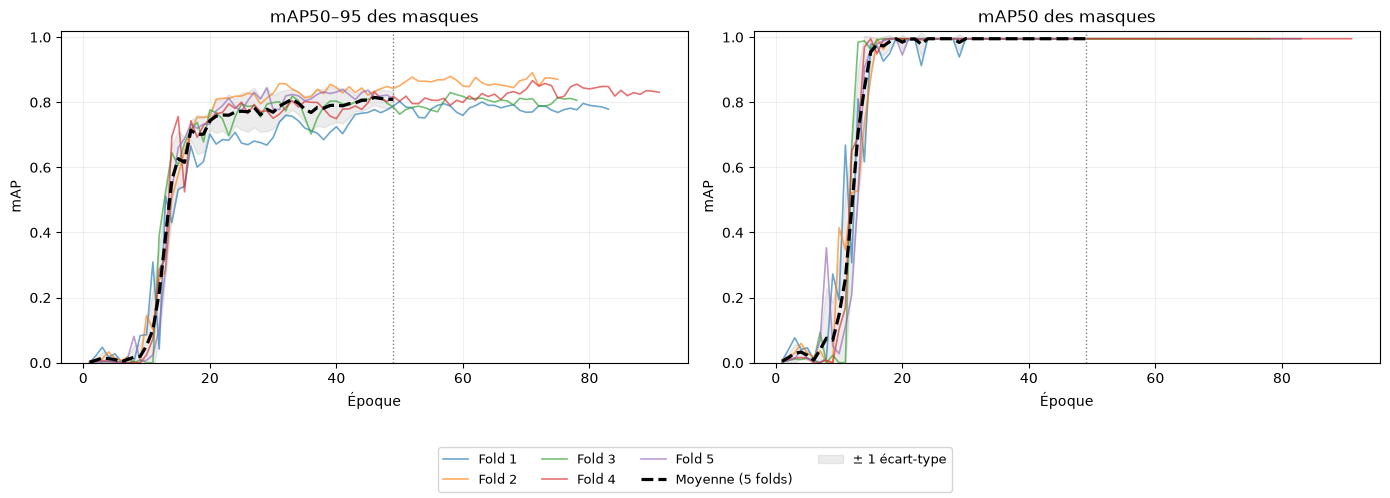

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(axes, ['metrics/mAP50-95(M)', 'metrics/mAP50(M)'],
                            ['mAP50–95 des masques', 'mAP50 des masques']):
    plot_folds(ax, metric, title, 'mAP', bounded=True)
finish_figure(fig, 'training_mask_map')

## 4. Courbes d’apprentissage de la segmentation
Comparer les tendances entraînement/validation ; les augmentations peuvent rendre la perte d’entraînement plus élevée. Les bandes montrent ± un écart-type entre folds.

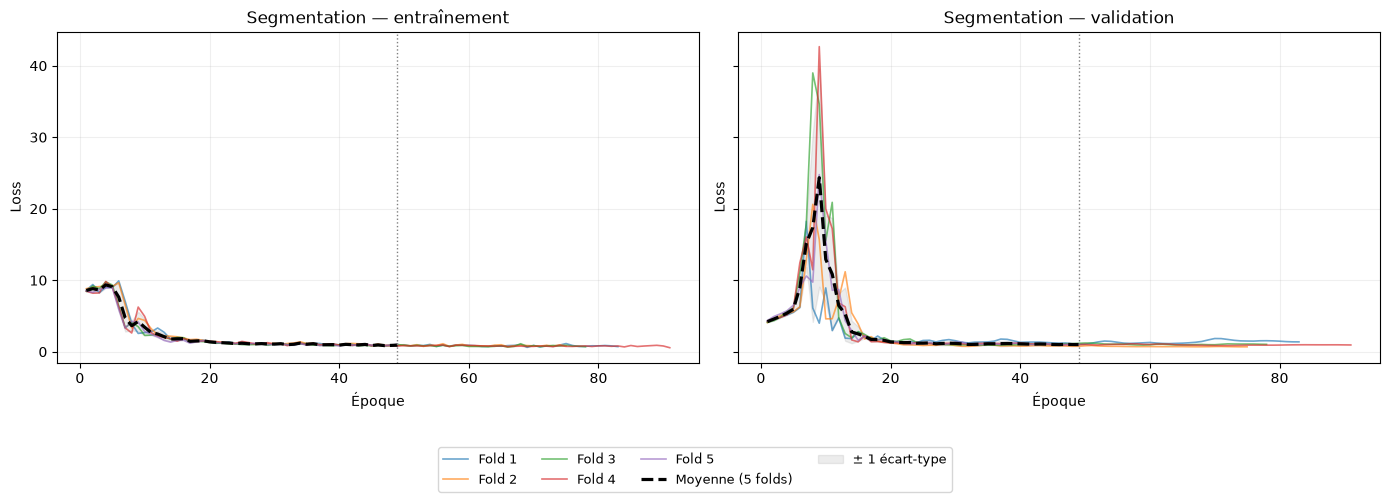

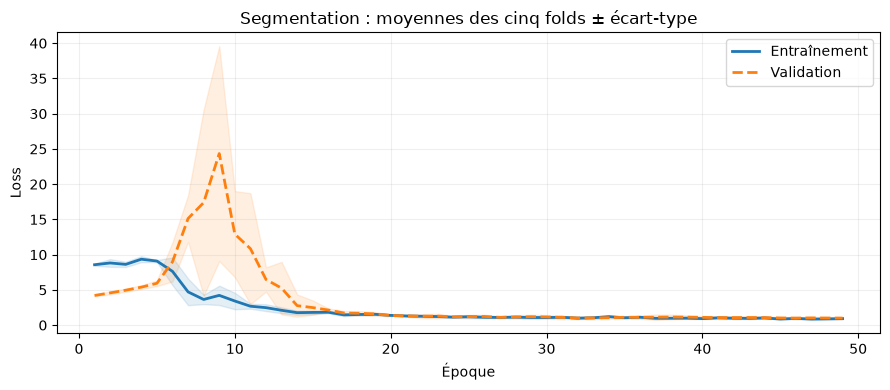

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_folds(axes[0], 'train/seg_loss', 'Segmentation — entraînement', 'Loss')
plot_folds(axes[1], 'val/seg_loss', 'Segmentation — validation', 'Loss')
finish_figure(fig, 'training_segmentation_losses')

fig, ax = plt.subplots(figsize=(9, 4))
for metric, label, color, style in [('train/seg_loss', 'Entraînement', 'tab:blue', '-'),
                                     ('val/seg_loss', 'Validation', 'tab:orange', '--')]:
    values = np.stack([h.loc[common_epochs, metric].to_numpy() for h in histories.values()])
    mean, std = values.mean(0), values.std(0, ddof=1)
    ax.plot(common_epochs, mean, label=label, color=color, ls=style, lw=2)
    ax.fill_between(common_epochs, mean-std, mean+std, color=color, alpha=.12)
ax.set(xlabel='Époque', ylabel='Loss', title='Segmentation : moyennes des cinq folds ± écart-type')
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
training_figures['training_segmentation_mean_comparison'] = fig
plt.show()

## 5. Diagnostics complémentaires
Précision/rappel des objets, calendrier du taux d’apprentissage, pertes de localisation et classification. Activer `SHOW_EXTRA_LOSSES` pour les pertes auxiliaires disponibles. Une validation sémantique toujours nulle n’est pas une segmentation parfaite.

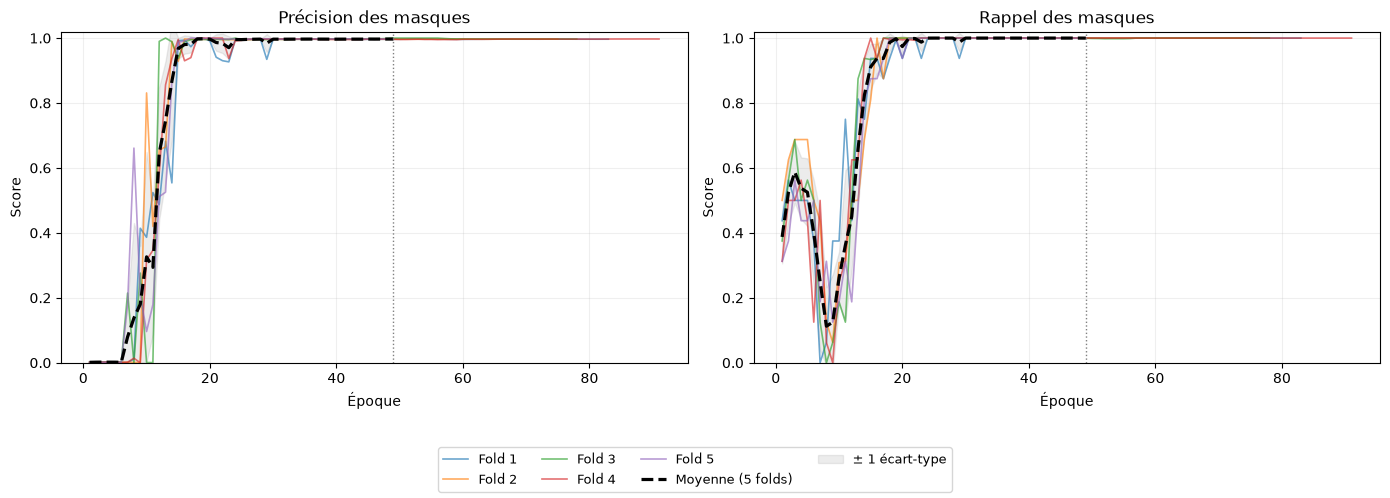

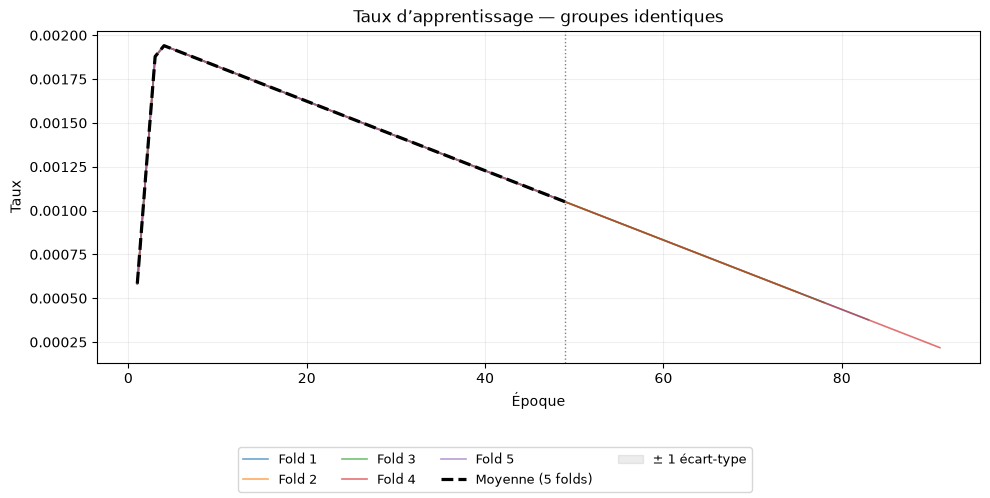

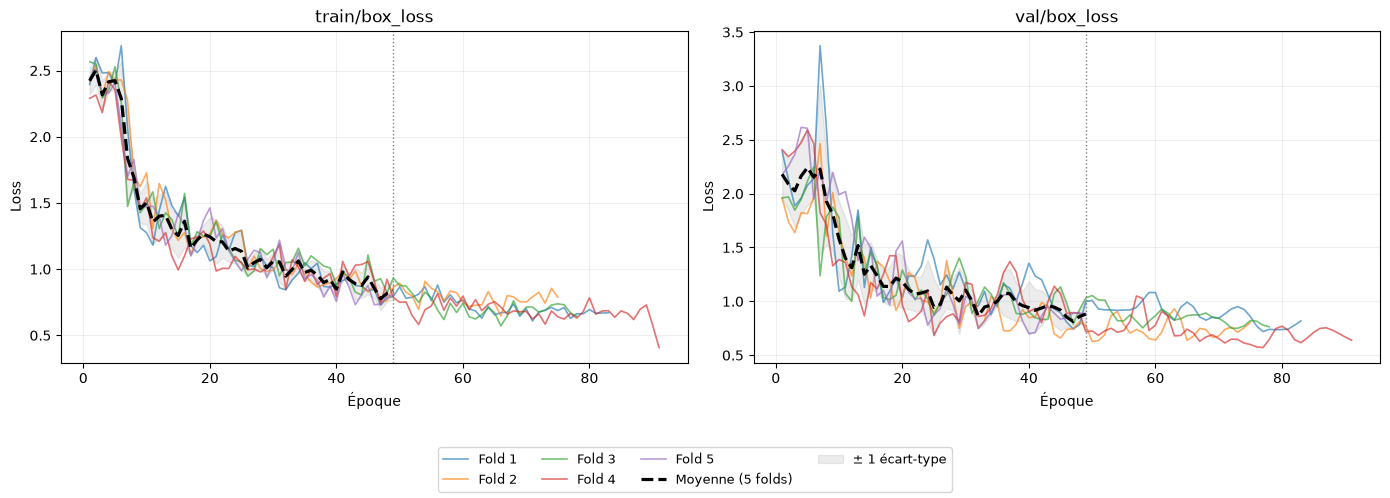

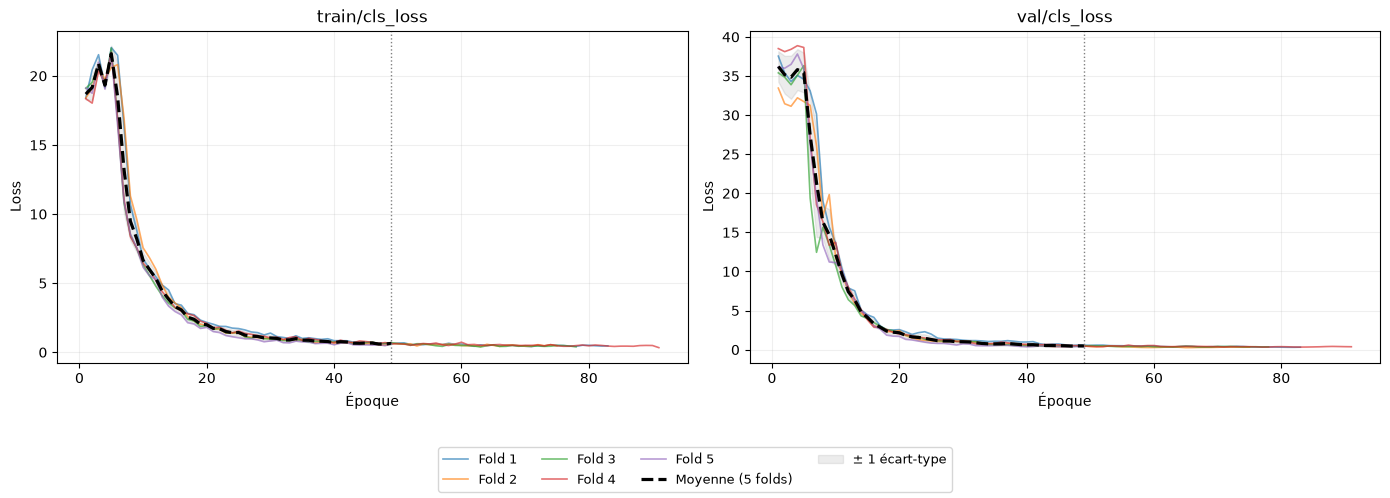

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(axes, ['metrics/precision(M)', 'metrics/recall(M)'],
                            ['Précision des masques', 'Rappel des masques']):
    plot_folds(ax, metric, title, 'Score', bounded=True)
finish_figure(fig, 'training_precision_recall')

lr_columns = [c for c in training_history.columns if c.startswith('lr/')]
identical_lr = all(np.allclose(h[c], h['lr/pg0']) for h in histories.values() for c in lr_columns)
if identical_lr:
    fig, ax = plt.subplots(figsize=(10, 5))
    plot_folds(ax, 'lr/pg0', 'Taux d’apprentissage — groupes identiques', 'Taux')
else:
    fig, axes = plt.subplots(1, len(lr_columns), figsize=(6*len(lr_columns), 5), squeeze=False)
    for ax, metric in zip(axes[0], lr_columns):
        plot_folds(ax, metric, metric, 'Taux')
finish_figure(fig, 'training_learning_rate')

losses = ['box_loss', 'cls_loss']
if SHOW_EXTRA_LOSSES:
    losses += [loss for loss in ['l1_loss', 'dfl_loss', 'sem_loss']
               if all(f'train/{loss}' in h.columns and f'val/{loss}' in h.columns for h in histories.values())]
for loss in losses:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, split in zip(axes, ['train', 'val']):
        metric = f'{split}/{loss}'
        if all((h[metric] == 0).all() for h in histories.values()):
            ax.text(.5, .5, 'Toujours nulle : non informative', ha='center', transform=ax.transAxes)
            ax.set_title(metric)
        else:
            plot_folds(ax, metric, metric, 'Loss')
    finish_figure(fig, f'training_{loss}')

## 6. Bilan des checkpoints retenus
Métriques de validation finale enregistrées dans chaque `best.pt`, jamais maxima indépendants des colonnes du CSV. L’époque reste indisponible si elle a été supprimée. Les moyennes et écarts-types sont non pondérés entre folds.

In [72]:
# Local checkpoints from this experiment only. No inference or training here.
checkpoint_rows = []
metric_names = {'mask_mAP50_95': 'metrics/mAP50-95(M)', 'mask_mAP50': 'metrics/mAP50(M)',
                'mask_precision': 'metrics/precision(M)', 'mask_recall': 'metrics/recall(M)'}
for fold in FOLDS:
    checkpoint = RUN_ROOT / f'fold_{fold}' / 'weights' / 'best.pt'
    saved = torch.load(checkpoint, map_location='cpu', weights_only=False)
    metrics = saved.get('train_metrics') or {}
    if any(key not in metrics for key in metric_names.values()):
        raise ValueError(f'Métriques du checkpoint indisponibles : {checkpoint}')
    epoch = saved.get('epoch', -1)
    # Stripped checkpoints use -1. Embedded train_results may contain the entire
    # run, so its last row does not reliably identify the selected epoch.
    best_epoch = int(epoch) + 1 if epoch is not None and epoch >= 0 else pd.NA
    checkpoint_rows.append(dict(fold=fold, best_epoch=best_epoch,
                                metric_source='best.pt: train_metrics (validation finale)',
                                **{name: float(metrics[key]) for name, key in metric_names.items()}))
    del saved
checkpoint_metrics = pd.DataFrame(checkpoint_rows)
checkpoint_metrics['best_epoch'] = checkpoint_metrics.best_epoch.astype('Int64')
overview['best_epoch'] = overview.fold.map(checkpoint_metrics.set_index('fold').best_epoch).astype('Int64')
checkpoint_summary = checkpoint_metrics[list(metric_names)].agg(['mean', 'std'])
print('Époque <NA> : information supprimée du checkpoint ; aucun maximum de CSV substitué.')
display(overview.round(3))
display(checkpoint_metrics.round(4))
display(checkpoint_summary.round(4))

# Add markers only when the checkpoint explicitly retained its epoch.
for row in checkpoint_metrics.itertuples():
    if pd.notna(row.best_epoch) and row.best_epoch in histories[row.fold].index:
        for ax, metric in zip(training_figures['training_mask_map'].axes,
                              ['metrics/mAP50-95(M)', 'metrics/mAP50(M)']):
            ax.scatter([row.best_epoch], [histories[row.fold].loc[row.best_epoch, metric]],
                       color=FOLD_COLORS[row.fold], marker='*', s=100, zorder=5)

Époque <NA> : information supprimée du checkpoint ; aucun maximum de CSV substitué.


,fold,train_images,val_images,train_patients,val_patients,epochs_completed,training_minutes,best_epoch
0,1,64,16,34,8,83,3.415,<NA>
1,2,64,16,34,8,75,3.324,<NA>
2,3,64,16,34,8,78,3.378,<NA>
3,4,64,16,33,9,91,4.054,<NA>
4,5,64,16,33,9,49,2.146,<NA>


,fold,best_epoch,metric_source,mask_mAP50_95,mask_mAP50,mask_precision,mask_recall
0,1,<NA>,best.pt: train_metrics (validation finale),0.8009,0.995,0.9965,1.0
1,2,<NA>,best.pt: train_metrics (validation finale),0.8626,0.995,0.9966,1.0
2,3,<NA>,best.pt: train_metrics (validation finale),0.8297,0.995,0.9978,1.0
3,4,<NA>,best.pt: train_metrics (validation finale),0.8663,0.995,0.9968,1.0
4,5,<NA>,best.pt: train_metrics (validation finale),0.8445,0.995,0.9976,1.0


,mask_mAP50_95,mask_mAP50,mask_precision,mask_recall
mean,0.8408,0.995,0.9971,1.0
std,0.0267,0.000,0.0006,0.0


## 7. Inférence et métriques par image
Dice et IoU évaluent le recouvrement (1 = parfait). L'erreur de surface signée vaut `(surface prédite − surface référence) / surface référence` ; positive = surestimation. Sa valeur absolue mesure l'ampleur de l'erreur.

Le centre est le barycentre des pixels du masque. La distance normalisée est divisée par le diamètre équivalent du masque de référence `2√(surface/π)` ; elle est sans unité. Les distances en pixels ne sont pas des distances physiques.

`retina_masks=True` demande des masques aux dimensions originales. Le notebook vérifie les dimensions et s'arrête en cas de désaccord, sans redimensionnement approximatif. Les masques binaires retournés par Ultralytics sont utilisés tels quels. Aucun choix de masque ne dépend de l'annotation.

In [73]:
def measure_masks(pred, ref):
    dice, iou = overlap_scores(pred, ref)
    area_ref, area_pred = int(ref.sum()), int(pred.sum())
    relative = (area_pred - area_ref) / area_ref
    if area_pred:
        center_ref = np.argwhere(ref).mean(axis=0)
        center_pred = np.argwhere(pred).mean(axis=0)
        distance = float(np.linalg.norm(center_pred - center_ref))
    else:
        distance = np.nan
    return dict(dice=dice, iou=iou, area_ref_px=area_ref, area_pred_px=area_pred,
                area_error_signed=relative, area_error_abs=abs(relative),
                center_distance_px=distance,
                center_distance_normalized=distance / (2 * np.sqrt(area_ref / np.pi)))

# Contrôles indépendants sur des cas simples, sans inférence.
r = np.zeros((8, 8), bool); r[2:6, 2:6] = True
assert measure_masks(r, r)['dice'] == 1
assert measure_masks(r, r)['iou'] == 1
z = measure_masks(np.zeros_like(r), r)
assert z['dice'] == z['iou'] == 0 and z['area_error_signed'] == -1
assert np.isnan(z['center_distance_px'])
p = np.zeros_like(r); p[2:6, 4:8] = True
s = measure_masks(p, r)
assert np.isclose(s['dice'], 0.5) and np.isclose(s['iou'], 1/3)
assert np.isclose(s['center_distance_px'], 2)
print('Calcul des métriques vérifié sur masques synthétiques.')

Calcul des métriques vérifié sur masques synthétiques.


In [74]:
rows, predicted_masks = [], {}
for fold in range(1, 6):
    checkpoint = RUN_ROOT / f'fold_{fold}' / 'weights' / 'best.pt'
    model = YOLO(str(checkpoint))
    for image in sorted(splits[fold]['val']):
        name = paths[image]
        ref = reference_masks[name]
        result = model.predict(source=str(image), imgsz=IMGSZ, conf=CONF, device=DEVICE,
                               classes=[0], retina_masks=True, augment=False,
                               save=False, verbose=False)[0]
        count = len(result.boxes) if result.boxes is not None else 0
        confidence = np.nan
        pred = np.zeros_like(ref)
        if count:
            if result.masks is None or len(result.masks.data) != count:
                raise ValueError(f'Boîtes et masques incohérents : {name}')
            index = int(result.boxes.conf.argmax().item())
            confidence = float(result.boxes.conf[index].item())
            raw = result.masks.data[index].detach().cpu().numpy()
            if raw.shape != ref.shape:
                raise ValueError(f'Dimensions prédites {raw.shape} != référence {ref.shape} : {name}')
            pred = raw > 0.5
        predicted_masks[name] = pred
        info = metadata.set_index('NAME').loc[name]
        rows.append(dict(NAME=name, PATIENT=info.PATIENT, SIDE=info.SIDE, fold=fold,
                         confidence=confidence, n_predictions=count,
                         missing_detection=count == 0, multiple_predictions=count > 1,
                         empty_selected_mask=count > 0 and not pred.any(),
                         **measure_masks(pred, ref)))
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f'Fold {fold}/5 terminé.')
per_image = pd.DataFrame(rows).sort_values(['fold', 'NAME']).reset_index(drop=True)
assert len(per_image) == len(metadata) and per_image.NAME.is_unique
if per_image.groupby('PATIENT').fold.nunique().max() != 1:
    raise ValueError('Un patient apparaît dans plusieurs folds.')
display(per_image)

Fold 1/5 terminé.
Fold 2/5 terminé.
Fold 3/5 terminé.
Fold 4/5 terminé.
Fold 5/5 terminé.


,NAME,PATIENT,SIDE,fold,confidence,n_predictions,missing_detection,multiple_predictions,empty_selected_mask,dice,iou,area_ref_px,area_pred_px,area_error_signed,area_error_abs,center_distance_px,center_distance_normalized
0,0016.png,RAS,L,1,0.887935,1,False,False,False,0.979945,0.960678,7704,7803,0.012850,0.012850,0.549433,0.005548
1,0017.png,RAS,R,1,0.887140,1,False,False,False,0.930147,0.869415,6305,7252,0.150198,0.150198,0.682672,0.007619
2,0030.png,KIS,L,1,0.918407,1,False,False,False,0.972825,0.947087,8732,9115,0.043862,0.043862,1.778571,0.016868
3,0031.png,KIS,R,1,0.933674,1,False,False,False,0.976983,0.955002,9738,9335,-0.041384,0.041384,0.480555,0.004316
4,0032.png,KAS,L,1,0.901256,1,False,False,False,0.968592,0.939096,10798,10693,-0.009724,0.009724,2.624447,0.022383
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,0063.png,TOJ,R,5,0.880799,1,False,False,False,0.934780,0.877546,7388,7638,0.033839,0.033839,5.028558,0.051847
76,0068.png,MAH,L,5,0.864410,1,False,False,False,0.924545,0.859679,8849,10010,0.131201,0.131201,4.044632,0.038105
77,0069.png,MAH,R,5,0.633878,1,False,False,False,0.924139,0.858977,9068,9756,0.075871,0.075871,3.614994,0.033643
78,0078.png,GEPT,L,5,0.888432,1,False,False,False,0.953858,0.911786,8818,9300,0.054661,0.054661,1.889811,0.017835


### Synthèse par patient, fold et ensemble
**Résultat principal :** moyenne du Dice et de l'IoU par patient, puis moyenne sur les patients. Les yeux disponibles d'un patient ont le même poids entre eux ; chaque patient a ensuite le même poids.

Les autres métriques sont également moyennées par patient. Les distances de centre excluent les masques vides : les effectifs valides et les échecs sont toujours rapportés. Les statistiques par image et par fold sont complémentaires. Les erreurs de surface et distances normalisées sont exportées en fractions (0,10 = 10 %).

L'IC à 95 % utilise un bootstrap percentile de 10 000 tirages de patients, avec remise. Il conserve implicitement leurs yeux ensemble en rééchantillonnant les moyennes par patient. Il est descriptif, conditionnel aux modèles et partitions existants : il ne mesure pas l'incertitude d'un nouvel entraînement et ne corrige pas la sélection des checkpoints sur validation.

In [75]:
METRICS = ['dice', 'iou', 'area_error_signed', 'area_error_abs',
           'center_distance_px', 'center_distance_normalized']
per_patient = per_image.groupby(['PATIENT', 'fold'], as_index=False)[METRICS].mean()
patient_counts = per_image.groupby(['PATIENT', 'fold'], as_index=False).agg(
    n_images=('NAME', 'size'), n_missing=('missing_detection', 'sum'),
    n_multiple=('multiple_predictions', 'sum'), n_empty_masks=('empty_selected_mask', 'sum'),
    n_valid_centers=('center_distance_px', 'count'))
per_patient = per_patient.merge(patient_counts, on=['PATIENT', 'fold'], validate='one_to_one')

def descriptive(frame, level):
    return pd.DataFrame([dict(level=level, metric=m, n_valid=frame[m].count(),
                              mean=frame[m].mean(), std=frame[m].std(),
                              median=frame[m].median(), q25=frame[m].quantile(.25),
                              q75=frame[m].quantile(.75), minimum=frame[m].min(),
                              maximum=frame[m].max()) for m in METRICS])

global_summary = pd.concat([descriptive(per_image, 'image'), descriptive(per_patient, 'patient')], ignore_index=True)
rng = np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_indices = rng.integers(0, len(per_patient), size=(BOOTSTRAP_REPEATS, len(per_patient)))
for metric in ['dice', 'iou']:
    values = per_patient[metric].to_numpy()
    low, high = np.quantile(values[bootstrap_indices].mean(axis=1), [.025, .975])
    target = (global_summary.level == 'patient') & (global_summary.metric == metric)
    global_summary.loc[target, ['ci95_low', 'ci95_high']] = [low, high]
fold_summaries = []
for fold in range(1, 6):
    for frame, level in [(per_image, 'image'), (per_patient, 'patient')]:
        part = descriptive(frame[frame.fold == fold], level)
        part.insert(0, 'fold', fold)
        fold_summaries.append(part)
fold_summary = pd.concat(fold_summaries, ignore_index=True)
failures = per_image.groupby('fold', as_index=False).agg(
    n_images=('NAME', 'size'), n_missing=('missing_detection', 'sum'),
    n_multiple=('multiple_predictions', 'sum'), n_empty_masks=('empty_selected_mask', 'sum'),
    n_valid_centers=('center_distance_px', 'count'))
display(global_summary.round(4))
patient_overview = global_summary[global_summary.level == 'patient'].copy()
display(patient_overview[['metric', 'n_valid', 'mean', 'std', 'median', 'ci95_low', 'ci95_high']].round(4))
display(fold_summary[fold_summary.metric.isin(['dice', 'iou'])].round(4))
display(failures)
print('Total des échecs et prédictions multiples :')
display(failures.drop(columns='fold').sum().to_frame('total'))

,level,metric,n_valid,mean,std,median,q25,q75,minimum,maximum,ci95_low,ci95_high
0,image,dice,80,0.9543,0.0250,0.9588,0.9414,0.9727,0.8696,0.9872,NaN,NaN
1,image,iou,80,0.9136,0.0446,0.9208,0.8892,0.9468,0.7693,0.9747,NaN,NaN
2,image,area_error_signed,80,0.0086,0.0756,0.0084,-0.0349,0.0433,-0.2269,0.2030,NaN,NaN
3,image,area_error_abs,80,0.0555,0.0518,0.0411,0.0216,0.0707,0.0007,0.2269,NaN,NaN
4,image,center_distance_px,80,2.3225,1.8300,1.8729,0.9188,2.9432,0.2574,9.0234,NaN,NaN
5,image,center_distance_normalized,80,0.0227,0.0173,0.0183,0.0085,0.0287,0.0020,0.0785,NaN,NaN
6,patient,dice,42,0.9538,0.0222,0.9583,0.9448,0.9697,0.8832,0.9856,0.9471,0.9602
7,patient,iou,42,0.9128,0.0396,0.9204,0.8961,0.9411,0.7910,0.9717,0.9008,0.9242
8,patient,area_error_signed,42,0.0111,0.0683,0.0061,-0.0156,0.0346,-0.2005,0.1603,NaN,NaN
9,patient,area_error_abs,42,0.0558,0.0467,0.0414,0.0264,0.0735,0.0025,0.2005,NaN,NaN


,metric,n_valid,mean,std,median,ci95_low,ci95_high
6,dice,42,0.9538,0.0222,0.9583,0.9471,0.9602
7,iou,42,0.9128,0.0396,0.9204,0.9008,0.9242
8,area_error_signed,42,0.0111,0.0683,0.0061,NaN,NaN
9,area_error_abs,42,0.0558,0.0467,0.0414,NaN,NaN
10,center_distance_px,42,2.3695,1.4399,1.9163,NaN,NaN
11,center_distance_normalized,42,0.0232,0.0139,0.0191,NaN,NaN


,fold,level,metric,n_valid,mean,std,median,q25,q75,minimum,maximum
0,1,image,dice,16,0.9497,0.0370,0.9663,0.9390,0.9739,0.8696,0.9872
1,1,image,iou,16,0.9064,0.0648,0.9348,0.8850,0.9491,0.7693,0.9747
6,1,patient,dice,8,0.9497,0.0349,0.9607,0.9423,0.9705,0.8832,0.9856
7,1,patient,iou,8,0.9064,0.0612,0.9249,0.8918,0.9426,0.7910,0.9717
12,2,image,dice,16,0.9614,0.0200,0.9694,0.9450,0.9795,0.9201,0.9831
13,2,image,iou,16,0.9263,0.0367,0.9406,0.8957,0.9598,0.8520,0.9667
18,2,patient,dice,8,0.9614,0.0168,0.9634,0.9529,0.9762,0.9288,0.9770
19,2,patient,iou,8,0.9263,0.0308,0.9301,0.9102,0.9535,0.8672,0.9551
24,3,image,dice,16,0.9520,0.0241,0.9516,0.9447,0.9710,0.9049,0.9835
25,3,image,iou,16,0.9094,0.0436,0.9077,0.8952,0.9437,0.8263,0.9675


,fold,n_images,n_missing,n_multiple,n_empty_masks,n_valid_centers
0,1,16,0,0,0,16
1,2,16,0,0,0,16
2,3,16,0,0,0,16
3,4,16,0,0,0,16
4,5,16,0,0,0,16


Total des échecs et prédictions multiples :


,total
n_images,80
n_missing,0
n_multiple,0
n_empty_masks,0
n_valid_centers,80


## 8. Distributions et comparaison des folds
Les points sont les images, colorées par fold. Les boîtes montrent médiane, quartiles et dispersion. La ligne zéro sépare sous-estimation et surestimation de surface. Les centres indisponibles sont exclus du panneau correspondant ; les échecs restent rapportés dans les tableaux. Les folds ont des patients différents : leur classement ne suffit pas à choisir un modèle final.
Une seconde figure présente les mêmes distributions **par patient** : chaque point est la moyenne des vues disponibles d'un patient, avec un poids égal pour chaque patient. Pour les distances de centre, seules les vues dont le centre est disponible contribuent à cette moyenne ; les effectifs et échecs restent indiqués dans les tableaux. Les deux figures sont exportées séparément.


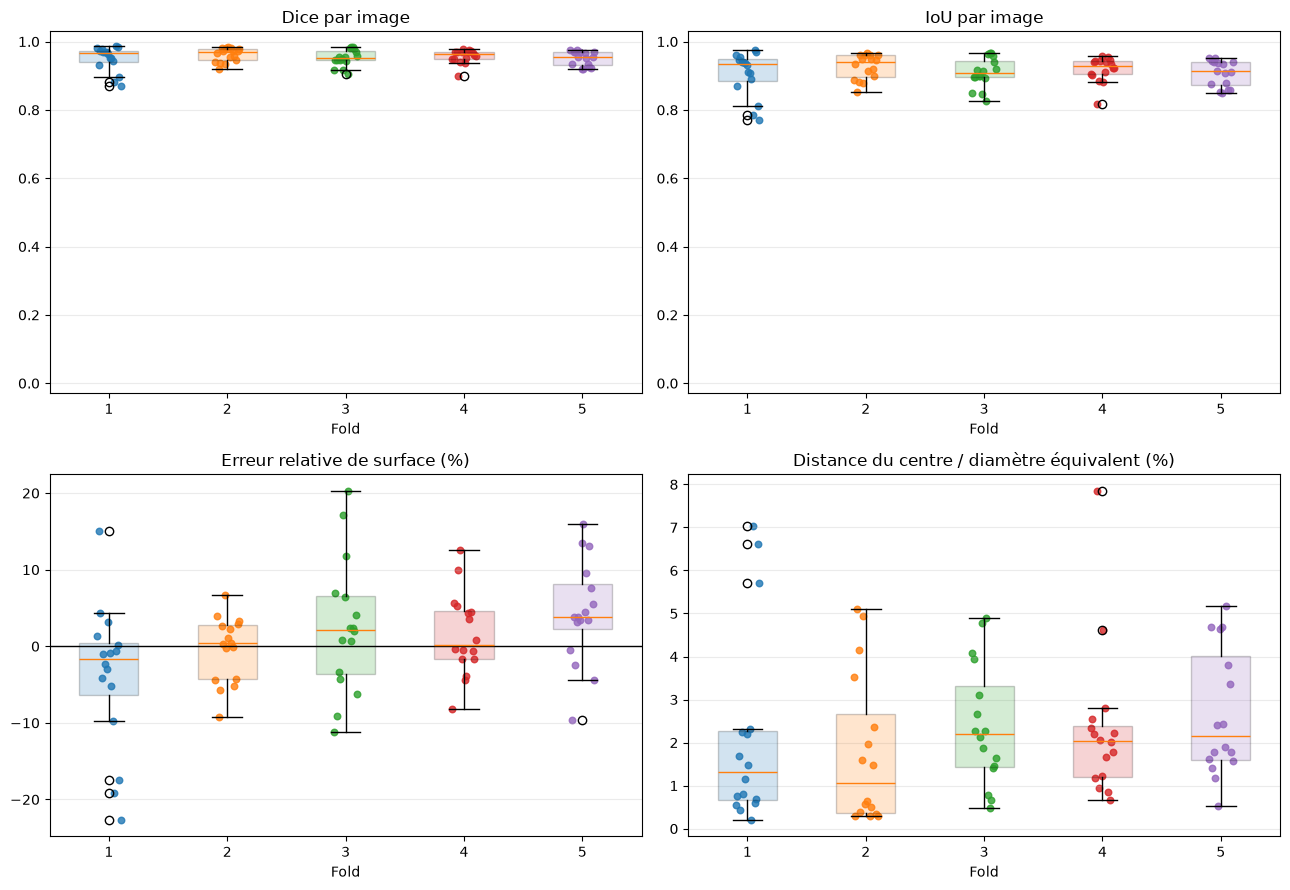

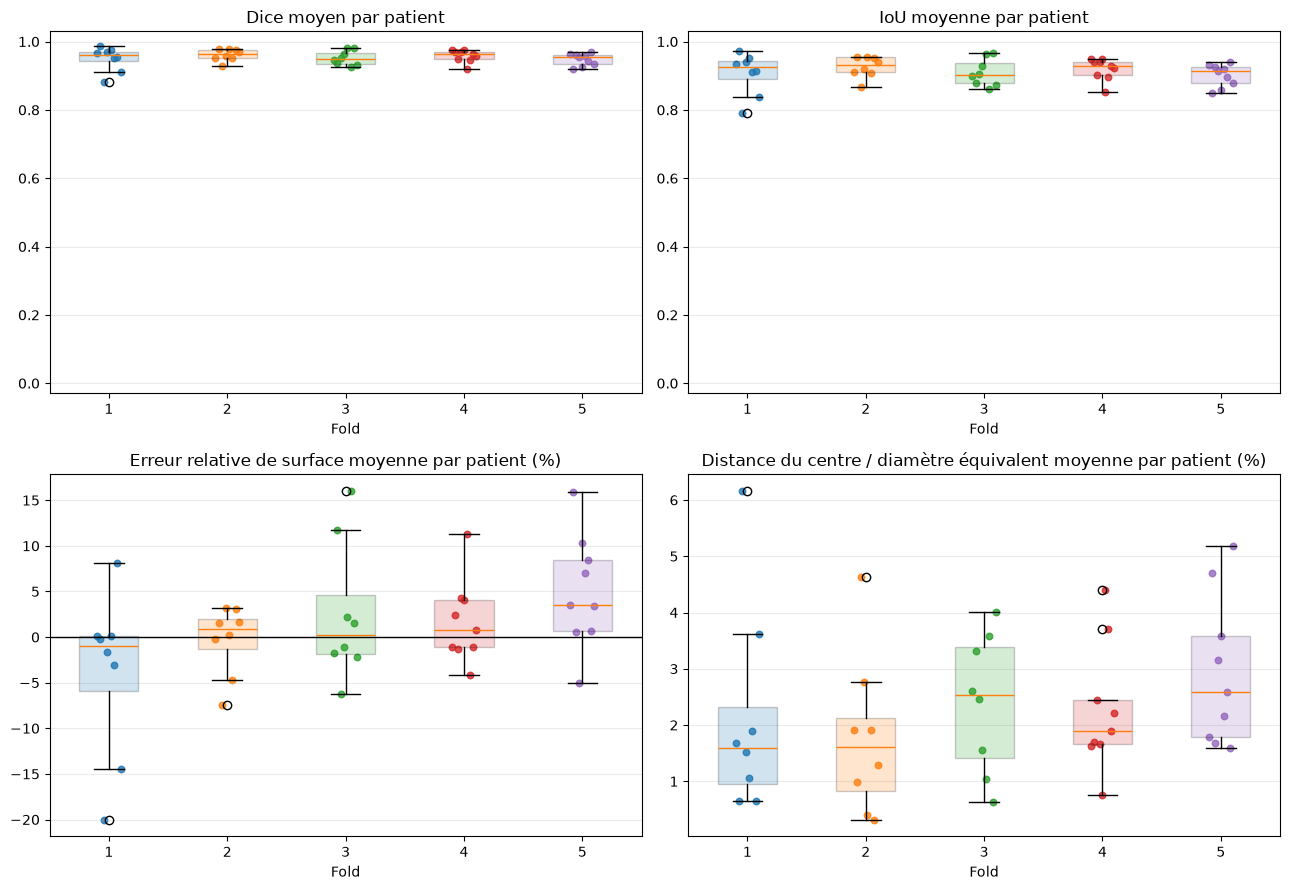

In [76]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, metric, title, factor in zip(axes.flat,
        ['dice', 'iou', 'area_error_signed', 'center_distance_normalized'],
        ['Dice par image', 'IoU par image', 'Erreur relative de surface (%)',
         'Distance du centre / diamètre équivalent (%)'], [1, 1, 100, 100]):
    groups = [factor * per_image.loc[per_image.fold == f, metric].dropna().to_numpy() for f in FOLDS]
    boxes = ax.boxplot(groups, patch_artist=True)
    for f, box, values in zip(FOLDS, boxes['boxes'], groups):
        box.set_facecolor(FOLD_COLORS[f]); box.set_alpha(.2)
        ax.scatter(f + np.linspace(-.1, .1, len(values)), values,
                   color=FOLD_COLORS[f], s=22, alpha=.8)
    ax.set(xlabel='Fold', title=title)
    ax.grid(axis='y', alpha=.25)
    if metric in ['dice', 'iou']:
        ax.set_ylim(-.03, 1.03)
    elif metric == 'area_error_signed':
        ax.axhline(0, color='black', lw=1)
fig.tight_layout()
plt.show()
summary_figure = fig

# Complement the image-level distributions with one observation per patient.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, metric, title, factor in zip(axes.flat,
        ['dice', 'iou', 'area_error_signed', 'center_distance_normalized'],
        ['Dice moyen par patient', 'IoU moyenne par patient',
         'Erreur relative de surface moyenne par patient (%)',
         'Distance du centre / diamètre équivalent moyenne par patient (%)'],
        [1, 1, 100, 100]):
    groups = [factor * per_patient.loc[per_patient.fold == f, metric].dropna().to_numpy()
              for f in FOLDS]
    boxes = ax.boxplot(groups, patch_artist=True)
    for f, box, values in zip(FOLDS, boxes['boxes'], groups):
        box.set_facecolor(FOLD_COLORS[f]); box.set_alpha(.2)
        ax.scatter(f + np.linspace(-.1, .1, len(values)), values,
                   color=FOLD_COLORS[f], s=22, alpha=.8)
    ax.set(xlabel='Fold', title=title)
    ax.grid(axis='y', alpha=.25)
    if metric in ['dice', 'iou']:
        ax.set_ylim(-.03, 1.03)
    elif metric == 'area_error_signed':
        ax.axhline(0, color='black', lw=1)
fig.tight_layout()
plt.show()
patient_summary_figure = fig


## 9. Inspection des contours
Vert = PNG de référence ; magenta = prédiction. Les cas sont classés après évaluation pour expliquer les résultats, pas pour modifier les règles du benchmark. Les deux panneaux permettent de comparer le contour de référence seul et sa superposition à la prédiction.

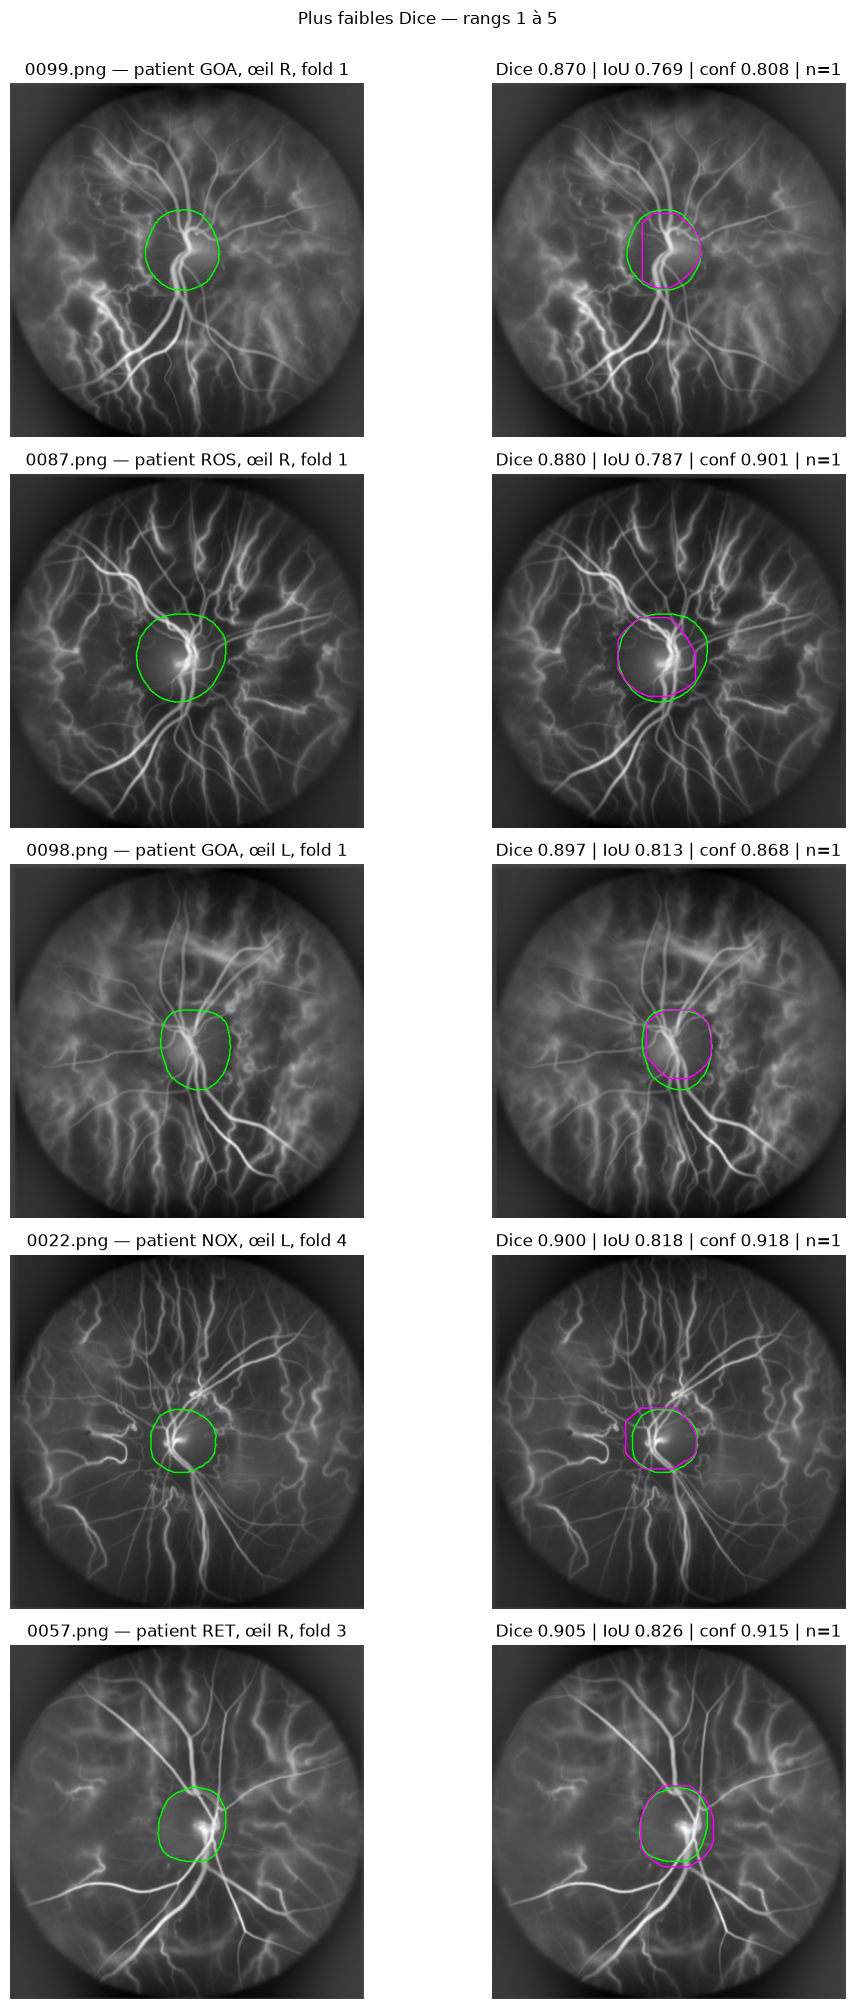

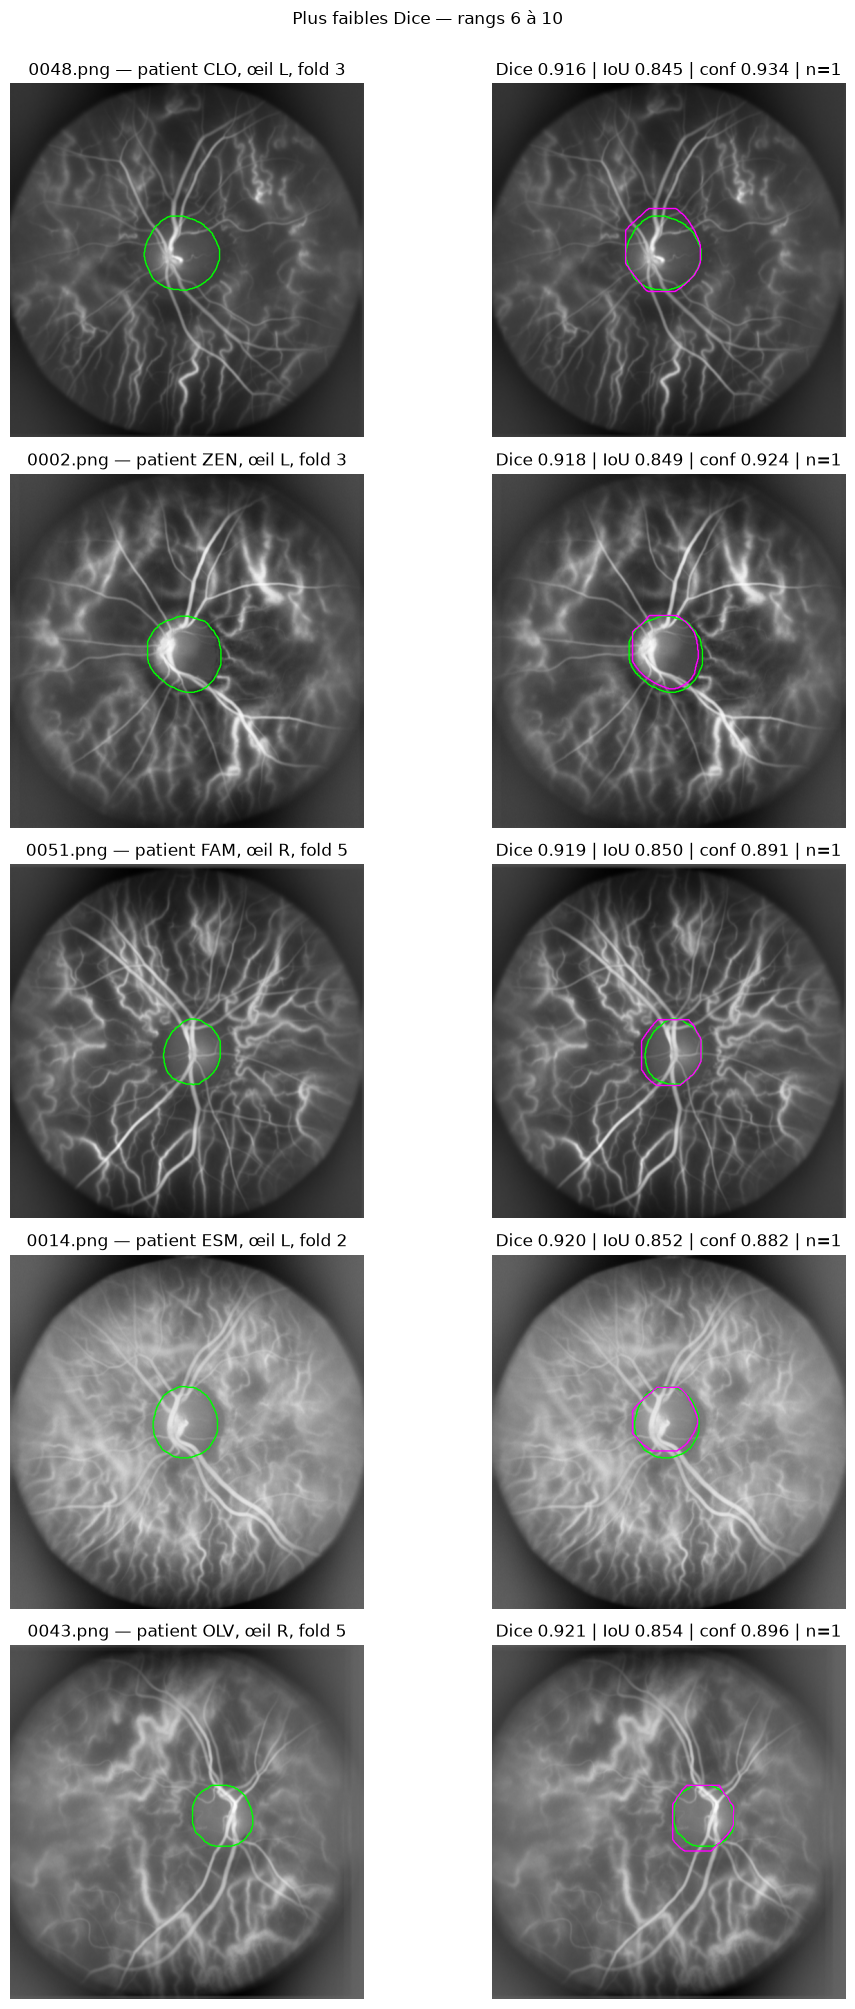

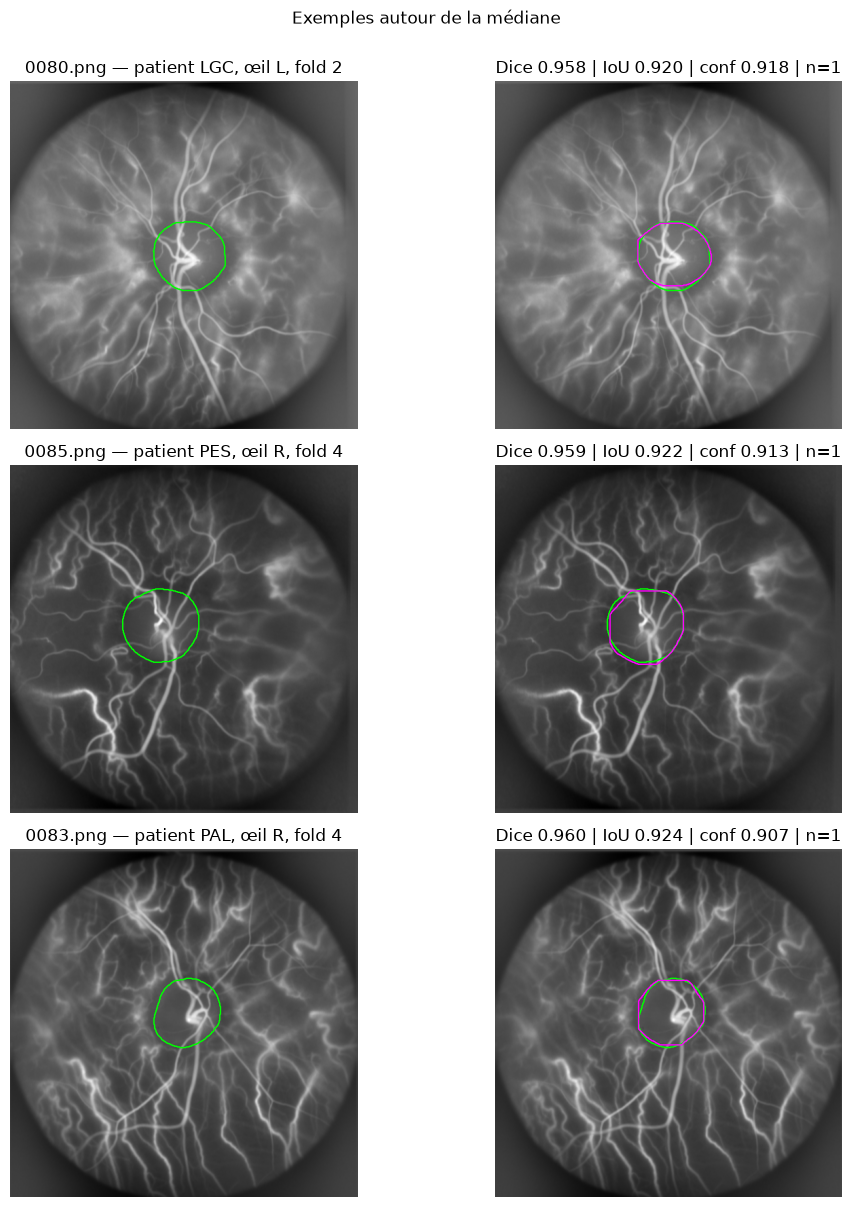

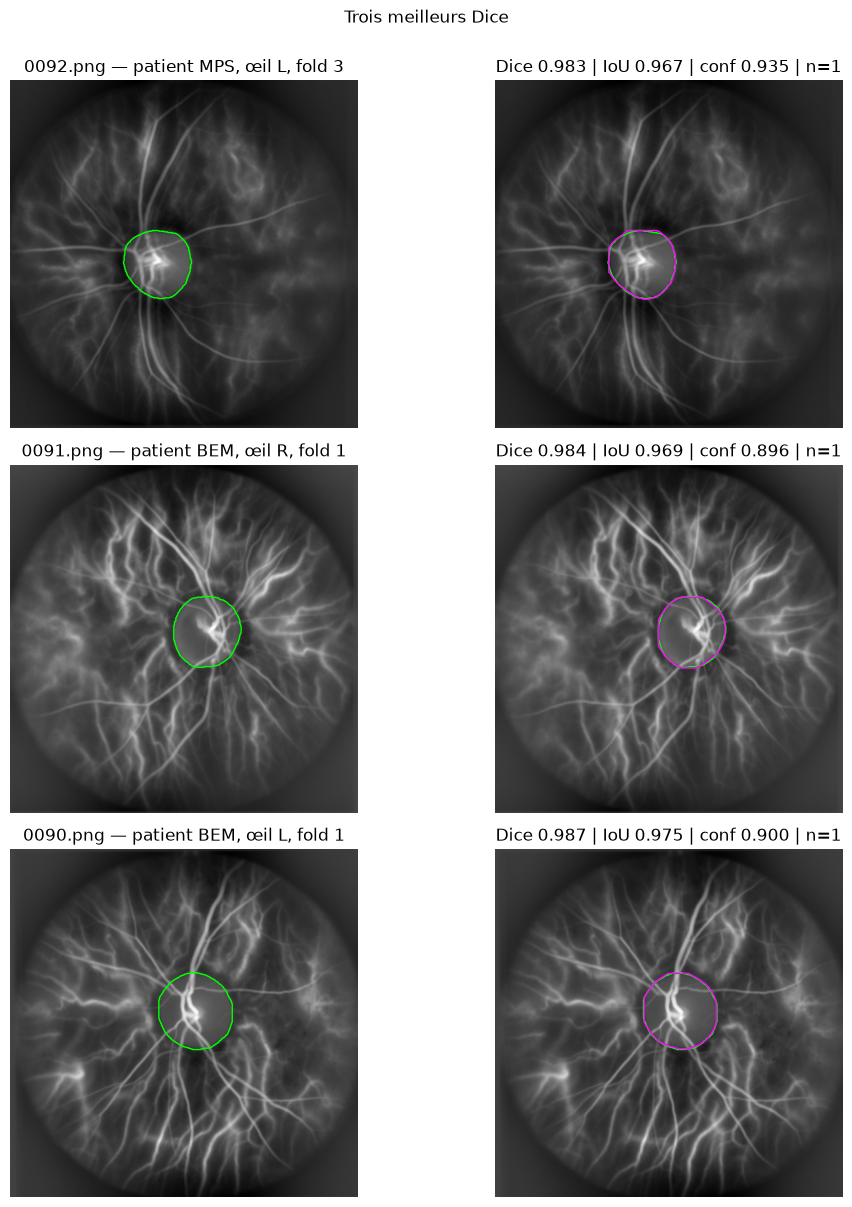

In [77]:
def gallery(frame, title):
    fig, axes = plt.subplots(len(frame), 2, figsize=(11, 4 * len(frame)), squeeze=False)
    for axes_row, row in zip(axes, frame.itertuples()):
        image = cv2.cvtColor(cv2.imread(str(DATASET / 'images' / row.NAME)), cv2.COLOR_BGR2RGB)
        ref, pred = reference_masks[row.NAME], predicted_masks[row.NAME]
        for ax in axes_row:
            ax.imshow(image, origin='upper')
            ax.contour(np.arange(-1, ref.shape[1] + 1),
                       np.arange(-1, ref.shape[0] + 1),
                       np.pad(ref.astype(float), 1), levels=[.5],
                       colors='lime', linewidths=1)
            ax.set_xlim(-.5, ref.shape[1]-.5); ax.set_ylim(ref.shape[0]-.5, -.5)
            ax.axis('off')
        if pred.any():
            # Padding keeps contours visible when a mask touches an image border.
            axes_row[1].contour(np.arange(-1, pred.shape[1] + 1),
                                np.arange(-1, pred.shape[0] + 1),
                                np.pad(pred.astype(float), 1), levels=[.5],
                                colors='magenta', linewidths=1)
        axes_row[0].set_title(f'{row.NAME} — patient {row.PATIENT}, œil {row.SIDE}, fold {row.fold}')
        axes_row[1].set_title(f'Dice {row.dice:.3f} | IoU {row.iou:.3f} | conf {row.confidence:.3f} | n={row.n_predictions}')
    fig.suptitle(title, y=1.002)
    fig.tight_layout()
    plt.show()
    return fig

ordered = per_image.sort_values(['dice', 'NAME']).reset_index(drop=True)
gallery_figures = []
# Small batches keep figures readable and avoid excessively tall images.
for start in range(0, min(10, len(ordered)), 5):
    gallery_figures.append((f'worst_{start+1:02d}', gallery(ordered.iloc[start:start+5], f'Plus faibles Dice — rangs {start+1} à {min(start+5, len(ordered), 10)}')))
mid = len(ordered) // 2
gallery_figures.append(('median', gallery(ordered.iloc[max(0, mid-1):mid+2], 'Exemples autour de la médiane')))
gallery_figures.append(('best', gallery(ordered.tail(3), 'Trois meilleurs Dice')))
if SHOW_ALL:
    for start in range(0, len(per_image), 5):
        fig = gallery(per_image.iloc[start:start+5], f'Toutes les images — lot {start//5+1}')
        plt.close(fig)

## 10. Sauvegarder le benchmark
Cette cellule crée uniquement un nouveau sous-dossier de `runs/benchmarks/`. Les entraînements et annotations sont conservés. Les masques retenus sont aussi enregistrés pour permettre un contrôle ultérieur. Une valeur de centre absente reste vide dans les CSV, jamais remplacée par zéro.

In [78]:
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
OUTPUT = ROOT / 'runs' / 'benchmarks' / f'{EXPERIMENT}_{stamp}'
OUTPUT.mkdir(parents=True, exist_ok=False)
for name, table in [('training_history', training_history), ('training_overview', overview),
                    ('checkpoint_metrics', checkpoint_metrics),
                    ('checkpoint_summary', checkpoint_summary.rename_axis('statistic').reset_index()),
                    ('patient_overview', patient_overview), ('per_image', per_image), ('per_patient', per_patient),
                    ('global_summary', global_summary), ('fold_summary', fold_summary),
                    ('failures_by_fold', failures), ('partitions', partitions),
                    ('polygon_png_consistency', consistency)]:
    table.to_csv(OUTPUT / f'{name}.csv', index=False, encoding='utf-8-sig')
mask_dir = OUTPUT / 'predicted_masks'
mask_dir.mkdir()
for name, mask in predicted_masks.items():
    if not cv2.imwrite(str(mask_dir / f'{Path(name).stem}_pred.png'), mask.astype(np.uint8) * 255):
        raise IOError(f'Échec de sauvegarde du masque : {name}')
summary_figure.savefig(OUTPUT / 'metric_distributions.png', dpi=160, bbox_inches='tight')
patient_summary_figure.savefig(OUTPUT / 'patient_metric_distributions.png', dpi=160, bbox_inches='tight')
for name, fig in training_figures.items():
    fig.savefig(OUTPUT / f'{name}.png', dpi=180, bbox_inches='tight')
    fig.savefig(OUTPUT / f'{name}.pdf', bbox_inches='tight')
for name, fig in gallery_figures:
    fig.savefig(OUTPUT / f'gallery_{name}.png', dpi=140, bbox_inches='tight')
versions = {name: importlib.metadata.version(name) for name in
            ['ultralytics', 'torch', 'numpy', 'pandas', 'opencv-python', 'matplotlib']}
manifest = dict(experiment=EXPERIMENT, created_utc=stamp, root=str(ROOT),
                imgsz=IMGSZ, confidence=CONF, device=str(DEVICE), retina_masks=True,
                selection='highest confidence among class 0 predictions; no morphological postprocessing',
                reference='binary PNG at original resolution',
                missing='Dice/IoU=0, signed area error=-1, center unavailable',
                primary_aggregation='mean of per-patient means',
                bootstrap=dict(seed=BOOTSTRAP_SEED, repeats=BOOTSTRAP_REPEATS,
                               unit='patient', method='percentile', metrics=['dice', 'iou']),
                training_curves=dict(common_epochs=common_epochs, mean='unweighted over all five folds',
                                     spread='sample standard deviation, ddof=1; not a confidence interval',
                                     interpolation=False, extrapolation=False,
                                     checkpoint_epoch='unavailable when stripped; never inferred from metric maxima',
                                     checkpoint_metrics='best.pt train_metrics, final validation'),
                versions=versions, python=platform.python_version(),
                checkpoints=[dict(fold=f, path=str(RUN_ROOT / f'fold_{f}' / 'weights' / 'best.pt')) for f in range(1, 6)])
(OUTPUT / 'benchmark_config.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
print('Résultats sauvegardés :', OUTPUT)

Résultats sauvegardés : C:\Users\pierr\Desktop\working\CNRS\workspace\runs\benchmarks\yolo26n_seg_512_seed42_r_softgeom_20261113T164628_708269Z


## Lire les résultats
- Lire d'abord mAP50–95(M) et les pertes de segmentation pour comprendre convergence et variabilité.
- Une perte de validation qui augmente pendant que celle d'entraînement baisse peut signaler du surapprentissage. Les augmentations rendent toutefois la comparaison des niveaux absolus délicate.
- La précision et le rappel concernent les objets appariés, pas les pixels. La mAP agrège plusieurs seuils de confiance et diffère du protocole d'inférence fixé à 0,25.
- Les métriques historiques utilisent la validation Ultralytics ; Dice/IoU sont calculés séparément sur les PNG aux dimensions originales, uniquement pour les checkpoints retenus. Aucune courbe de Dice par époque n'est reconstruite.
- Pour le résultat final, privilégier les moyennes par patient de Dice/IoU, les IC descriptifs et les échecs. Les IC ne corrigent pas la sélection sur validation.
- La moyenne des cinq folds s'arrête à leur dernière époque commune. La dispersion entre folds n'est pas un intervalle de confiance.
- Aucun entraînement, changement de seuil ou sélection de cas ne découle automatiquement de ces graphiques.